Dataset path: /kaggle/input/datasets/adityajn105/flickr8k
                       image  \
0  1000268201_693b08cb0e.jpg   
1  1000268201_693b08cb0e.jpg   
2  1000268201_693b08cb0e.jpg   
3  1000268201_693b08cb0e.jpg   
4  1000268201_693b08cb0e.jpg   

                                             caption  
0  A child in a pink dress is climbing up a set o...  
1              A girl going into a wooden building .  
2   A little girl climbing into a wooden playhouse .  
3  A little girl climbing the stairs to her playh...  
4  A little girl in a pink dress going into a woo...  
Total captions: 40455
Caption 1: A large wild cat is pursuing a horse across a meadow .
Caption 2: Two brown dogs fight on the leafy ground .
Caption 3: A man in shorts is standing on a rock looking out at the view from the hilltop .


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

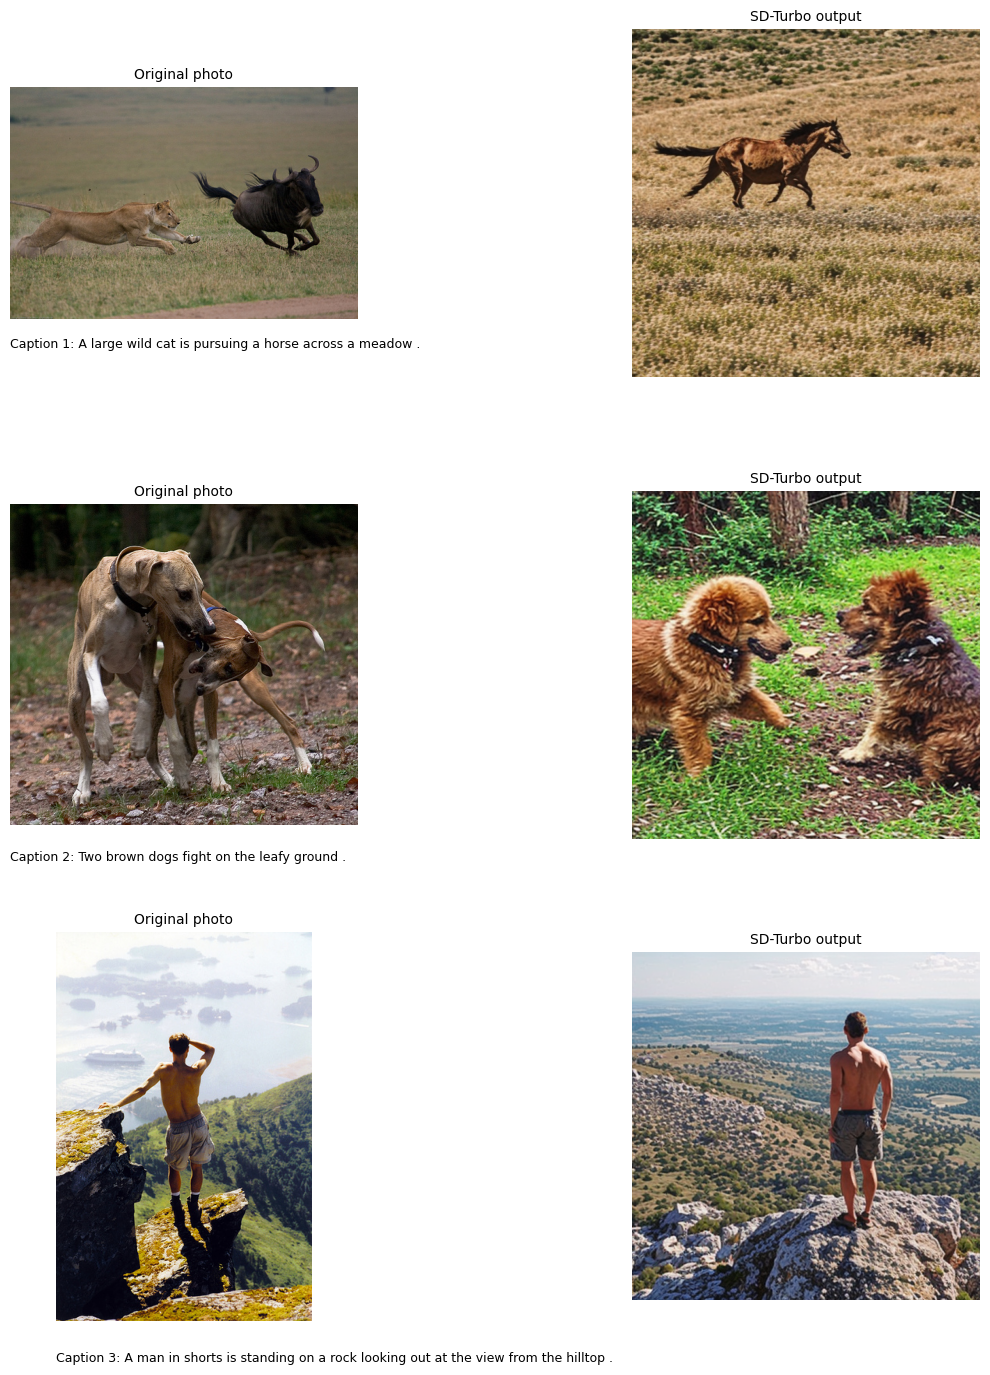

In [5]:
import os
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("adityajn105/flickr8k")
print("Dataset path:", path)

captions = pd.read_csv(os.path.join(path, "captions.txt"))  # columns: image, caption
print(captions.head())
print("Total captions:", len(captions))

samples = captions.sample(3, random_state=42).reset_index(drop=True)
prompts = samples["caption"].tolist()

for i, p in enumerate(prompts, 1):
    print(f"Caption {i}: {p}")

# %% 2. LOAD A PRETRAINED MODEL
import torch
from diffusers import AutoPipelineForText2Image

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype,
    variant="fp16" if device == "cuda" else None,
).to(device)

# %% 3. GENERATE (one image per caption)
# SD-Turbo: very few steps, guidance scale 0
generated = []
for p in prompts:
    img = pipe(prompt=p, num_inference_steps=2, guidance_scale=0.0).images[0]
    generated.append(img)

# %% 4. EVALUATE (compare by hand using the rubric)
import matplotlib.pyplot as plt
from PIL import Image

img_dir = os.path.join(path, "Images")  # original Flickr8k photos

fig, axes = plt.subplots(3, 2, figsize=(10, 14))
for i in range(3):
    # Original photo (for reference)
    orig_path = os.path.join(img_dir, samples["image"][i])
    if os.path.exists(orig_path):
        axes[i, 0].imshow(Image.open(orig_path))
    axes[i, 0].set_title("Original photo", fontsize=10)
    axes[i, 0].axis("off")

    # Generated image
    axes[i, 1].imshow(generated[i])
    axes[i, 1].set_title("SD-Turbo output", fontsize=10)
    axes[i, 1].axis("off")

    # Caption under the row
    axes[i, 0].text(
        0, -0.08, f"Caption {i+1}: {prompts[i]}",
        transform=axes[i, 0].transAxes, fontsize=9, wrap=True, va="top",
    )

plt.tight_layout()

Caption 1: A child sitting on a stool eating icecream.
Caption 2: A kitten sleeping on a cushion .
Caption 3: two toddlers eating lollipops.


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

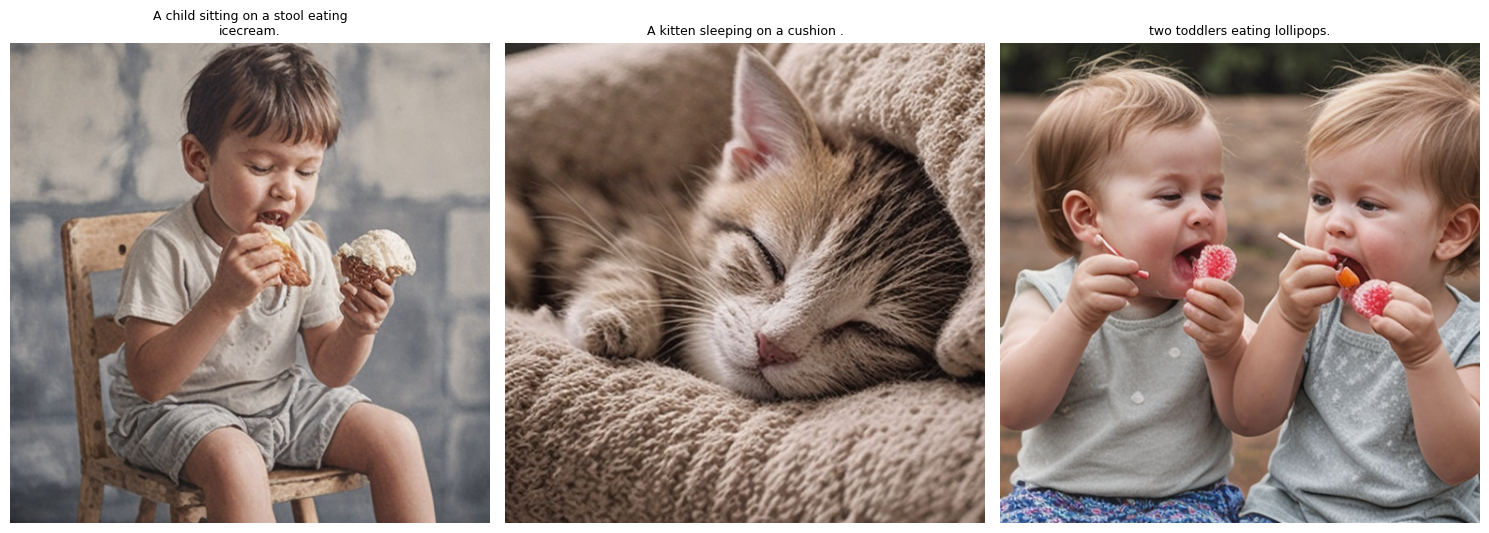

In [15]:
prompts = [
    "A child sitting on a stool eating icecream.",
    "A kitten sleeping on a cushion .",
    "two toddlers eating lollipops.",
]

for i, p in enumerate(prompts, 1):
    print(f"Caption {i}: {p}")

# %% 2. LOAD A PRETRAINED MODEL
import torch
from diffusers import AutoPipelineForText2Image

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype,
    variant="fp16" if device == "cuda" else None,
).to(device)

# %% 3. GENERATE (one image per caption)
# SD-Turbo: very few steps, guidance scale 0
generated = []
for p in prompts:
    img = pipe(prompt=p, num_inference_steps=2, guidance_scale=0.0).images[0]
    generated.append(img)

# %% 4. EVALUATE (compare by hand using the rubric)
import matplotlib.pyplot as plt
import textwrap

fig, axes = plt.subplots(1, len(prompts), figsize=(5 * len(prompts), 6))
if len(prompts) == 1:
    axes = [axes]

for ax, img, p in zip(axes, generated, prompts):
    ax.imshow(img)
    ax.set_title(textwrap.fill(p, 40), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

Sample captions from Flickr8k:
                           image  \
17775  2973269132_252bfd0160.jpg   
13506   270263570_3160f360d3.jpg   
4325   2053006423_6adf69ca67.jpg   

                                                 caption  
17775  A large wild cat is pursuing a horse across a ...  
13506         Two brown dogs fight on the leafy ground .  
4325   A man in shorts is standing on a rock looking ...  

Prompts that will be used:
Caption 1: A child sitting on a stool eating icecream.
Caption 2: A kitten sleeping on a cushion.
Caption 3: Two toddlers eating lollipops.

Device being used: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


...

Saved: /kaggle/working/generated_images/generated_image_1.png

Generating image 2: A kitten sleeping on a cushion.


  0%|          | 0/2 [00:00<?, ?it/s]

Saved: /kaggle/working/generated_images/generated_image_2.png

Generating image 3: Two toddlers eating lollipops.


  0%|          | 0/2 [00:00<?, ?it/s]

Saved: /kaggle/working/generated_images/generated_image_3.png



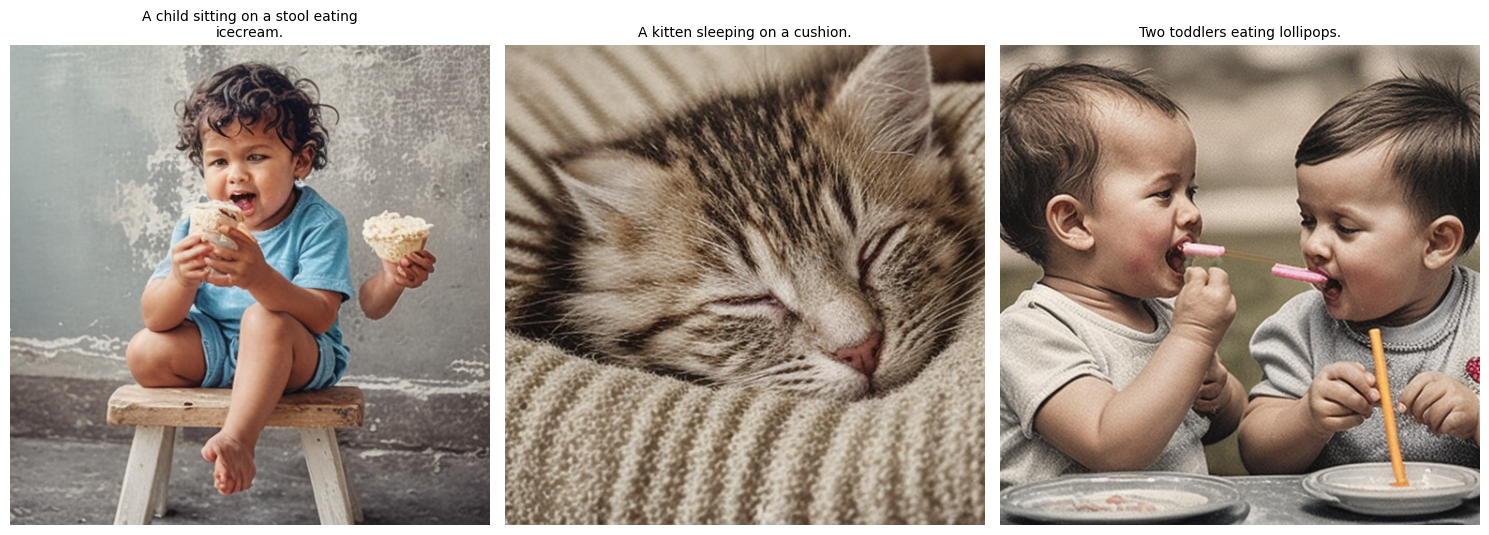


SAVED IMAGES
generated_image_3.png
generated_image_2.png
generated_image_1.png

Images are saved in:
/kaggle/working/generated_images


In [17]:
# ============================================
# 1. LOAD & INSPECT
# ============================================

import os
import kagglehub
import pandas as pd

# Download Flickr8k dataset
path = kagglehub.dataset_download("adityajn105/flickr8k")

# Load captions file
captions = pd.read_csv(
    os.path.join(path, "captions.txt")
)

# Display a few captions from the dataset
print("Sample captions from Flickr8k:")
print(captions.sample(3, random_state=42))


# ============================================
# 2. DEFINE PROMPTS
# ============================================

prompts = [
    "A child sitting on a stool eating icecream.",
    "A kitten sleeping on a cushion.",
    "Two toddlers eating lollipops."
]

print("\nPrompts that will be used:")
for i, p in enumerate(prompts, 1):
    print(f"Caption {i}: {p}")


# ============================================
# 3. LOAD A PRETRAINED MODEL
# ============================================

import torch
from diffusers import AutoPipelineForText2Image

# Check whether GPU is available
device = "cuda" if torch.cuda.is_available() else "cpu"

# Use float16 on GPU to save memory
dtype = torch.float16 if device == "cuda" else torch.float32

print("\nDevice being used:", device)

# Load SD-Turbo
pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype,
    variant="fp16" if device == "cuda" else None,
).to(device)

print("SD-Turbo model loaded successfully!")


# ============================================
# 4. GENERATE AND SAVE IMAGES
# ============================================

# Create output folder inside Kaggle's working directory
output_dir = "/kaggle/working/generated_images"

os.makedirs(output_dir, exist_ok=True)

# Store generated images in memory
generated = []

print("\nGenerating images...\n")

for i, p in enumerate(prompts, 1):

    print(f"Generating image {i}: {p}")

    # Generate image
    img = pipe(
        prompt=p,
        num_inference_steps=2,
        guidance_scale=0.0
    ).images[0]

    # Store image for displaying later
    generated.append(img)

    # Save image as PNG
    filename = os.path.join(
        output_dir,
        f"generated_image_{i}.png"
    )

    img.save(filename)

    print(f"Saved: {filename}\n")


# ============================================
# 5. DISPLAY GENERATED IMAGES
# ============================================

import matplotlib.pyplot as plt
import textwrap

# Create one row with 3 images
fig, axes = plt.subplots(
    1,
    len(prompts),
    figsize=(15, 6)
)

# Handle the case where there is only one image
if len(prompts) == 1:
    axes = [axes]

# Display each image
for ax, img, p in zip(axes, generated, prompts):

    ax.imshow(img)

    # Display the prompt above the image
    ax.set_title(
        textwrap.fill(p, 40),
        fontsize=10
    )

    # Remove x/y axes
    ax.axis("off")

plt.tight_layout()
plt.show()


# ============================================
# 6. CHECK SAVED FILES
# ============================================

print("\n============================================")
print("SAVED IMAGES")
print("============================================")

saved_files = os.listdir(output_dir)

for file in saved_files:
    print(file)

print("\nImages are saved in:")
print(output_dir)